# 03 - Second-Purchase (Churn) Model

**Business question:** *Will a new customer come back for a second purchase within N days of the first one?*

Why not "classic" churn? 97.8% of customers bought on a single day, so almost everyone looks "churned" after the first order. The useful question for the business is the **second purchase**: if we can rank new customers by their chance of coming back, marketing can focus the second-purchase offer on the right people (see the *New high-value* segment in `02_rfm_segmentation.ipynb`).

- **Target = 1** if the customer bought again on a **different day** within the window (same-day orders are split baskets, not returns).
- **Churn probability** = 1 - probability of returning.
- Data: `rpt.vw_CustomerOrders` (delivered orders only).


## 1. Load data and build each customer's purchase days


In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path
from db_utils import read_view

sns.set_theme(style="whitegrid")
plt.rcParams["axes.titleweight"] = "bold"
BLUE = "#2a78d6"
IMG_DIR = Path("../images")

orders = read_view("vw_CustomerOrders")
orders["purchase_date"] = pd.to_datetime(orders["purchase_date"])
DATA_END = orders["purchase_date"].max()

# One row per customer per purchase DAY (same-day orders collapse into one)
days = (orders[["customer_key", "purchase_date"]].drop_duplicates()
        .sort_values(["customer_key", "purchase_date"]))
days["day_seq"] = days.groupby("customer_key").cumcount() + 1

cust = (days[days["day_seq"] == 1].set_index("customer_key")[["purchase_date"]]
        .rename(columns={"purchase_date": "first_date"})
        .join(days[days["day_seq"] == 2].set_index("customer_key")["purchase_date"].rename("second_date")))
cust["gap_days"] = (cust["second_date"] - cust["first_date"]).dt.days

print(f"Data ends: {DATA_END.date()}")
print(f"Customers: {len(cust):,} | with a 2nd purchase day: {cust['second_date'].notna().sum():,}")

Data ends: 2018-08-29
Customers: 93,350 | with a 2nd purchase day: 2,015


## 2. How long should the window be?

If the window is too short we miss many real returns; if it is too long, too few customers have enough history to be labelled.
To measure this fairly we only use customers whose first purchase was **at least 365 days before the data ends**, so everyone had a full year to come back.


Customers with 365+ days of history: 21,360 | of them returned (any time): 795

             returned_within_%  share_of_all_returns_%
window_days                                           
30                        0.68                   18.24
60                        1.06                   28.43
90                        1.35                   36.23
120                       1.62                   43.52
180                       2.13                   57.36
270                       2.75                   73.84
365                       3.33                   89.43


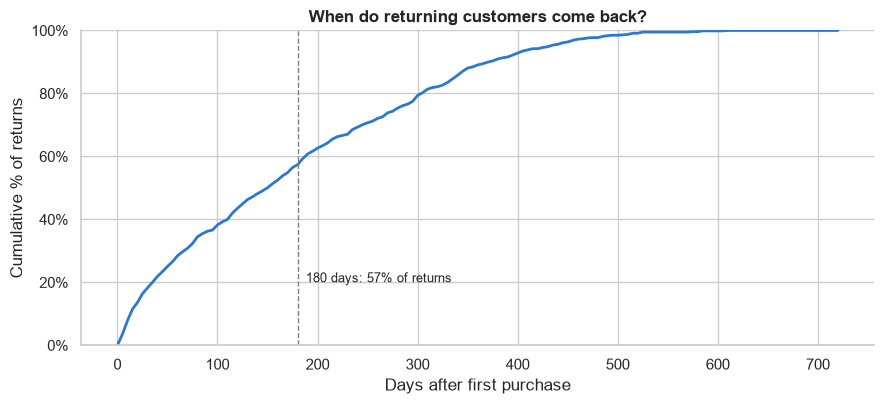

In [46]:
old = cust[cust["first_date"] <= DATA_END - pd.Timedelta(days=365)]
returners = old["gap_days"].dropna()
print(f"Customers with 365+ days of history: {len(old):,} | of them returned (any time): {len(returners):,}\n")

windows = [30, 60, 90, 120, 180, 270, 365]
coverage = pd.DataFrame({
    "window_days": windows,
    "returned_within_%": [(old["gap_days"] <= w).mean() * 100 for w in windows],
    "share_of_all_returns_%": [(returners <= w).mean() * 100 for w in windows],
}).set_index("window_days")
print(coverage.round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 4.2))
steps = np.arange(0, 721, 5)
ax.plot(steps, [(returners <= d).mean() * 100 for d in steps], color=BLUE, lw=2)
ax.axvline(180, color="gray", ls="--", lw=1)
ax.annotate(f"180 days: {(returners <= 180).mean():.0%} of returns", (180, 20), xytext=(6, 0),
            textcoords="offset points", fontsize=9)
ax.set_title("When do returning customers come back?")
ax.set_xlabel("Days after first purchase")
ax.set_ylabel("Cumulative % of returns")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, 100)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(IMG_DIR / "10_return_window.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Final target definition

- **Window = 180 days** after the first purchase.
- **Eligible customers**: first purchase between **2017-01-01** and **DATA_END - 180 days**, so every customer has the full 180 days observed (no customer is labelled "did not return" just because the data ended). 2016 is excluded because it has almost no orders.
- `returned_180 = 1` if the 2nd purchase day is within 180 days, else 0.


In [47]:
WINDOW = 180
LAST_FIRST_DATE = DATA_END - pd.Timedelta(days=WINDOW)

model_base = cust[(cust["first_date"] >= "2017-01-01") & (cust["first_date"] <= LAST_FIRST_DATE)].copy()
model_base["returned_180"] = (model_base["gap_days"] <= WINDOW).astype(int)   # NaN gap -> 0

n, pos = len(model_base), model_base["returned_180"].sum()
print(f"Eligible first purchases: {model_base['first_date'].min().date()} -> {model_base['first_date'].max().date()}")
print(f"Customers: {n:,} | returned within {WINDOW} days: {pos:,} ({pos / n:.2%}) | did not: {n - pos:,}")
print(f"Class ratio: about 1 returner for every {round((n - pos) / pos)} non-returners")

# Is the return rate stable over time? (a model trained on one period must work on another)
by_q = (model_base.groupby(model_base["first_date"].dt.to_period("Q"))["returned_180"]
        .agg(customers="size", return_rate_pct=lambda s: s.mean() * 100))
print()
print(by_q.round(2).to_string())

Eligible first purchases: 2017-01-05 -> 2018-03-02
Customers: 55,770 | returned within 180 days: 1,107 (1.98%) | did not: 54,663
Class ratio: about 1 returner for every 49 non-returners

            customers  return_rate_pct
first_date                            
2017Q1           4848             1.73
2017Q2           8743             2.24
2017Q3          11813             2.36
2017Q4          16725             1.76
2018Q1          13641             1.85


**Insight - the target is rare, stable over time, and the 180-day window is a deliberate trade-off**

- Among customers with a full year of history, only **3.3%** came back within 365 days. Returns are spread out: **30 days** catch 18% of them, **90 days** 36%, **180 days 57%**, 270 days 74%, 365 days 89%.
- **Why 180 days anyway?**
  - A longer window leaves fewer customers with enough history: 365 days would keep only first purchases up to Aug 2017 (~21k customers, ~700 returners) and no 2018 data at all.
  - 180 days keeps **55,770 customers** and **1,107 returners**, and includes **2018 Q1**, which we need to test the model on a later period than it was trained on.
  - Six months is a practical horizon for a marketing campaign.
  - So the model answers exactly: *"Will this customer return within 6 months?"*, not *"Will they ever return?"*. Some customers labelled 0 will come back later; that is a known limitation, stated clearly.
- **Base rate: 1.98%** (about 1 returner for every 49 non-returners). A model that always says "will not return" would be **98% accurate and useless**, so in 2.7-2.8 we will use **class weights** and judge the model with **Precision, Recall, ROC-AUC and PR-AUC**, never accuracy.
- The return rate is **stable across quarters (1.7%-2.4%)**, so training on 2017 and testing on 2018 Q1 is a fair check.


## 4. Prediction moment and leakage rules

The strongest signals from the EDA (late delivery, review score) only exist **after** the purchase. If we used them without care, the model would "see the future".

**Prediction moment = 30 days after the first purchase.** At that point:
- most orders are already delivered (average delivery 12.5 days) and reviewed, so the model can use **what was known on day 30**;
- 18% of all returns already happened before day 30 (section 2). Those customers have **already returned**, so they are removed from the model: there is nothing left to predict for them.

**Rules:**
1. Features use only the orders from the **first purchase day**.
2. Delivery and review information is used **only if it was available by day 30**:
   - `delivered_by_d30` - the first order arrived within 30 days;
   - `late_known_d30` - by day 30 the promised date had passed and the order had not arrived on time;
   - `review_d30` - review score, only when the order was delivered by day 30 (the view has no review date, so delivery by day 30 is used as the best available proxy - a stated limitation).
3. **Target** = returned between **day 31 and day 180**.
4. **Time-based split**: train on customers whose first purchase was in **2017**, test on **2018 (Jan - early Mar)**. A random split would mix periods and hide problems that appear when the model meets new customers.


In [48]:
PRED_DAY = 30

# Customers who already returned before the prediction moment are out of scope
base = model_base[~(model_base["gap_days"] <= PRED_DAY)].copy()
base["target"] = ((base["gap_days"] > PRED_DAY) & (base["gap_days"] <= WINDOW)).astype(int)   # NaN gap -> 0

print(f"Removed (returned within {PRED_DAY} days): {len(model_base) - len(base):,}")
print(f"Model customers: {len(base):,} | target = 1: {base['target'].sum():,} ({base['target'].mean():.2%})")

Removed (returned within 30 days): 361
Model customers: 55,409 | target = 1: 746 (1.35%)


## 5. Build features from the first purchase day


In [49]:
# Orders placed on each customer's first purchase day
fo = orders.merge(base[["first_date"]], left_on="customer_key", right_index=True)
fo = fo[fo["purchase_date"] == fo["first_date"]].copy()

# delay_days = delivered - estimated  ->  estimated delivery (days after purchase) = delivery_days - delay_days
fo["est_days"] = fo["delivery_days"] - fo["delay_days"]
fo["delivered_by_d30"] = fo["delivery_days"] <= PRED_DAY                                   # NaN -> False
fo["late_known_d30"] = (fo["est_days"] <= PRED_DAY) & (fo["delivery_days"] > fo["est_days"])
fo["delivery_days_d30"] = fo["delivery_days"].clip(upper=PRED_DAY).fillna(PRED_DAY)       # unknown = still waiting
fo["review_d30"] = fo["review_score"].where(fo["delivered_by_d30"])

feat = fo.groupby("customer_key").agg(
    first_revenue=("revenue", "sum"),
    first_freight=("freight_value", "sum"),
    first_items=("item_count", "sum"),
    first_orders=("order_id", "count"),               # >1 = split basket on day 1
    customer_state=("customer_state", "first"),
    delivered_by_d30=("delivered_by_d30", "all"),
    late_known_d30=("late_known_d30", "any"),
    delivery_days_d30=("delivery_days_d30", "max"),
    review_d30=("review_d30", "mean"),
)
feat["log_revenue"]   = np.log1p(feat["first_revenue"])
feat["freight_ratio"] = feat["first_freight"] / feat["first_revenue"]
feat["has_review_d30"] = feat["review_d30"].notna().astype(int)
feat["bad_review_d30"] = (feat["review_d30"] <= 2).astype(int)
feat["review_d30"]     = feat["review_d30"].fillna(0)                 # 0 = no review yet (see has_review_d30)
feat[["delivered_by_d30", "late_known_d30"]] = feat[["delivered_by_d30", "late_known_d30"]].astype(int)

data_m = base[["first_date", "target"]].join(feat)
print(f"Rows: {len(data_m):,} | missing feature rows: {data_m['first_revenue'].isna().sum()}")

Rows: 55,409 | missing feature rows: 0


In [50]:
# --- Time-based split ---
train_mask = data_m["first_date"] < "2018-01-01"
test_mask  = ~train_mask

# State: keep the 10 biggest states (measured on TRAIN only), group the rest as "Other"
top_states = data_m.loc[train_mask, "customer_state"].value_counts().head(10).index
data_m["state_grp"] = data_m["customer_state"].where(data_m["customer_state"].isin(top_states), "Other")
state_dummies = pd.get_dummies(data_m["state_grp"], prefix="state", dtype=int)

NUM_FEATURES = ["log_revenue", "freight_ratio", "first_items", "first_orders",
                "delivered_by_d30", "late_known_d30", "delivery_days_d30",
                "has_review_d30", "review_d30", "bad_review_d30"]
X = pd.concat([data_m[NUM_FEATURES], state_dummies], axis=1)
y = data_m["target"]

X_train, y_train = X[train_mask], y[train_mask]
X_test,  y_test  = X[test_mask],  y[test_mask]

print(f"Features: {X.shape[1]} ({len(NUM_FEATURES)} numeric + {state_dummies.shape[1]} state columns)")
print(f"Train (2017):        {len(X_train):>6,} customers | positives {y_train.sum():>4,} ({y_train.mean():.2%})")
print(f"Test  (2018 Jan-Mar): {len(X_test):>6,} customers | positives {y_test.sum():>4,} ({y_test.mean():.2%})")
assert X.isna().sum().sum() == 0, "There are missing values in the features"

Features: 21 (10 numeric + 11 state columns)
Train (2017):        41,845 customers | positives  570 (1.36%)
Test  (2018 Jan-Mar): 13,564 customers | positives  176 (1.30%)


In [51]:
# Sanity check on TRAIN only: does each feature differ between returners and non-returners?
check = (pd.concat([X_train[NUM_FEATURES], y_train], axis=1)
           .groupby("target").mean().T
           .rename(columns={0: "did_not_return", 1: "returned"}))
check["ratio"] = check["returned"] / check["did_not_return"]
print(check.round(3).to_string())

target             did_not_return  returned  ratio
log_revenue                 4.467     4.487  1.004
freight_ratio               0.304     0.301  0.992
first_items                 1.151     1.226  1.065
first_orders                1.011     1.037  1.025
delivered_by_d30            0.958     0.963  1.006
late_known_d30              0.046     0.049  1.073
delivery_days_d30          12.477    12.047  0.966
has_review_d30              0.952     0.958  1.006
review_d30                  4.046     4.143  1.024
bad_review_d30              0.095     0.084  0.886


### 5.1 Diagnostic: why is the lateness signal weaker than in the EDA?

In the EDA, customers with a late first order returned **35% less often**. Here the difference almost disappears. This cell checks where the effect goes, using the **train set only**.
`is_late_final` (lateness known only after delivery, any day) is used **here for diagnosis only, never as a model feature**.


In [52]:
diag = data_m.loc[train_mask, ["target"]].copy()
diag["late_known_d30"] = X_train["late_known_d30"]
diag["bad_review_d30"] = X_train["bad_review_d30"]
late_final = (fo.assign(late=pd.to_numeric(fo["is_late"], errors="coerce"))
                .groupby("customer_key")["late"].max())
diag["is_late_final"] = late_final.reindex(diag.index)

for col in ["late_known_d30", "is_late_final", "bad_review_d30"]:
    t = diag.groupby(col)["target"].agg(customers="size", returned="sum", return_rate_pct="mean")
    t["return_rate_pct"] *= 100
    print(f"--- {col} ---")
    print(t.round(2).to_string(), "\n")

# Same EDA population, but now: how many of the late-order returners came back within 30 days?
fo_all = orders.merge(model_base[["first_date"]], left_on="customer_key", right_index=True)
fo_all = fo_all[fo_all["purchase_date"] == fo_all["first_date"]]
late_all = pd.to_numeric(fo_all["is_late"], errors="coerce").groupby(fo_all["customer_key"]).max()
eda_like = model_base.join(late_all.rename("is_late_final"), how="inner")   # includes day 1-30 returners
eda_like["returned_any_180"] = (eda_like["gap_days"] <= WINDOW).astype(int)
eda_like["returned_le_30"]   = (eda_like["gap_days"] <= PRED_DAY).astype(int)
print(eda_like.groupby("is_late_final")[["returned_any_180", "returned_le_30"]].mean().mul(100).round(2).to_string())

--- late_known_d30 ---
                customers  returned  return_rate_pct
late_known_d30                                      
0                   39927       542             1.36
1                    1918        28             1.46 

--- is_late_final ---
               customers  returned  return_rate_pct
is_late_final                                      
0.0                39436       539             1.37
1.0                 2393        31             1.30 

--- bad_review_d30 ---
                customers  returned  return_rate_pct
bad_review_d30                                      
0                   37875       522             1.38
1                    3970        48             1.21 

               returned_any_180  returned_le_30
is_late_final                                  
0.0                        2.01            0.67
1.0                        1.59            0.36


**Insight - late delivery kills the *quick* second purchase, not the later ones**

- Model population: **55,409** customers (361 who returned within 30 days removed). Target = 1 for **746 (1.35%)**. Train 2017: 41,845 customers / **570** positives; test 2018 Jan-Mar: 13,564 / **176** positives. No missing values.
- In the model population (returns on day 31-180), lateness makes **no real difference**: 1.37% (on time) vs 1.30% (late, final status); 1.36% vs 1.46% for lateness known by day 30 (only 28 returners, too few to read anything).
- In the full eligible base the effect is there, and it sits in the **first 30 days**:
  - returned within 180 days: **2.01%** on time vs **1.59%** late (-21%);
  - returned within **30 days**: **0.67%** vs **0.36%** - late customers make about **half** as many quick repeat purchases.
- So a late first order mostly destroys the **fast follow-up purchase** (the strongest moment for a return, see the cohort analysis). After day 30, the customers who come back do so for reasons that lateness does not explain.
- Bad review by day 30 shows a small gap (1.21% vs 1.38%), also based on few returners.

**What this means for the model (honest expectation):**
- Using only information available on day 30, the individual-level signal is **weak**. We should expect a modest model (ROC-AUC clearly above 0.5, but far from perfect), and judge it on whether it **ranks** customers better than random for a marketing campaign.
- The lateness finding remains an **operational** recommendation: delivering on time protects the quick second purchase.
- If the model is too weak, the next features to try are product category, payment type / installments and seller (from the star schema), still taken from the first purchase day only.


## 6. Train the models

**The 2018 test set stays untouched until section 7.** All choices here (baselines, settings) are made inside 2017 only:
- **fit** on customers whose first purchase was **Jan - Sep 2017**,
- **validate** on **Oct - Dec 2017** (again a later period than the one used for fitting).

**Metrics** (accuracy is useless at a 1.4% positive rate):
- **ROC-AUC**: probability that a random returner gets a higher score than a random non-returner. 0.5 = random guessing.
- **PR-AUC** (average precision): how precise the top of the ranking is. Random guessing = the positive rate (~1.4%), so we also show **lift** = PR-AUC / positive rate.

**Class imbalance:** `class_weight="balanced"` makes each returner count ~70x more during training, so the model cannot ignore them.


In [53]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

# Time-based validation split INSIDE the 2017 training data
fit_mask = data_m.loc[X_train.index, "first_date"] < "2017-10-01"
X_fit, y_fit = X_train[fit_mask], y_train[fit_mask]
X_val, y_val = X_train[~fit_mask], y_train[~fit_mask]
base_rate = y_val.mean()
print(f"Fit (Jan-Sep 2017): {len(X_fit):,} customers, {y_fit.sum()} positives")
print(f"Val (Oct-Dec 2017): {len(X_val):,} customers, {y_val.sum()} positives (rate {base_rate:.2%})")

results = []
def score(name, settings, y_score):
    roc, pr = roc_auc_score(y_val, y_score), average_precision_score(y_val, y_score)
    results.append({"model": name, "settings": settings, "roc_auc": roc, "pr_auc": pr, "lift": pr / base_rate})

# --- Baselines: no model at all, just sort customers by one feature ---
score("Random", "-", np.random.default_rng(42).random(len(y_val)))
for f in ["log_revenue", "first_items", "review_d30"]:
    score("Baseline", f"sort by {f}", X_val[f])

Fit (Jan-Sep 2017): 25,223 customers, 378 positives
Val (Oct-Dec 2017): 16,622 customers, 192 positives (rate 1.16%)


In [54]:
# --- Logistic Regression: try a few regularisation strengths (C) ---
for C in [0.01, 0.1, 1.0, 10.0]:
    lr = make_pipeline(StandardScaler(),
                       LogisticRegression(C=C, class_weight="balanced", max_iter=2000))
    lr.fit(X_fit, y_fit)
    score("LogisticRegression", f"C={C}", lr.predict_proba(X_val)[:, 1])

# --- Random Forest: try a few tree sizes (bigger leaves = simpler trees, less overfitting) ---
for leaf in [20, 50, 100]:
    for depth in [8, None]:
        rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=leaf, max_depth=depth,
                                    class_weight="balanced_subsample", n_jobs=-1, random_state=42)
        rf.fit(X_fit, y_fit)
        score("RandomForest", f"min_leaf={leaf}, max_depth={depth}", rf.predict_proba(X_val)[:, 1])

val_tbl = pd.DataFrame(results)
print(val_tbl.round(3).to_string(index=False))

             model                     settings  roc_auc  pr_auc  lift
            Random                            -    0.484   0.011 0.993
          Baseline          sort by log_revenue    0.486   0.011 0.956
          Baseline          sort by first_items    0.514   0.012 1.080
          Baseline           sort by review_d30    0.510   0.012 1.023
LogisticRegression                       C=0.01    0.516   0.013 1.103
LogisticRegression                        C=0.1    0.517   0.013 1.104
LogisticRegression                        C=1.0    0.517   0.013 1.104
LogisticRegression                       C=10.0    0.517   0.013 1.104
      RandomForest     min_leaf=20, max_depth=8    0.528   0.013 1.112
      RandomForest  min_leaf=20, max_depth=None    0.526   0.013 1.142
      RandomForest     min_leaf=50, max_depth=8    0.526   0.013 1.117
      RandomForest  min_leaf=50, max_depth=None    0.531   0.013 1.138
      RandomForest    min_leaf=100, max_depth=8    0.533   0.013 1.156
      

### 6.1 Pick the best settings and refit on all of 2017

The best setting of each model is chosen by **validation ROC-AUC** (more stable than PR-AUC with only ~200 positives). Each model is then refit on the **full 2017** training set, ready for the one-time test in section 7.


In [55]:
best = (val_tbl[val_tbl["model"].isin(["LogisticRegression", "RandomForest"])]
        .sort_values("roc_auc", ascending=False)
        .groupby("model").head(1).set_index("model"))
print(best[["settings", "roc_auc", "pr_auc", "lift"]].round(3).to_string(), "\n")

def parse(settings):
    out = {}
    for part in settings.split(", "):
        k, v = part.split("=")
        out[k] = None if v == "None" else float(v) if "." in v else int(v)
    return out

lr_p = parse(best.loc["LogisticRegression", "settings"])
rf_p = parse(best.loc["RandomForest", "settings"])

final_lr = make_pipeline(StandardScaler(),
                         LogisticRegression(C=lr_p["C"], class_weight="balanced", max_iter=2000))
final_rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=rf_p["min_leaf"],
                                  max_depth=rf_p["max_depth"], class_weight="balanced_subsample",
                                  n_jobs=-1, random_state=42)
final_lr.fit(X_train, y_train)
final_rf.fit(X_train, y_train)
print("Final models trained on all 2017 customers:", f"{len(X_train):,}")

                                     settings  roc_auc  pr_auc   lift
model                                                                
RandomForest        min_leaf=100, max_depth=8    0.533   0.013  1.156
LogisticRegression                     C=10.0    0.517   0.013  1.104 

Final models trained on all 2017 customers: 41,845


### 6.2 First result: almost no signal -> add richer features

On validation, the best Random Forest reached ROC-AUC **0.533** and Logistic Regression **0.517**, while the *random* ordering scored **0.484**. With only 192 returners in validation, chance alone moves ROC-AUC by about ±0.03, so these models are **not reliably better than random**.

Before giving up, we try one organised round of **extra features from the star schema**. All of them are known **at the moment of the first purchase**, so they add no leakage:

| Feature | Source | Idea |
|---|---|---|
| `main_category` | `FactOrderItems` + `DimProduct` | Some categories are bought again (e.g. home items), others once (e.g. furniture) |
| `n_sellers`, `same_state_seller`, `distance_km` | `DimSeller` + `DimGeography` | Distance and number of sellers drive the delivery experience |
| `avg_weight_kg`, `avg_photos` | `DimProduct` | Product type / listing quality |
| `main_payment`, `max_installments`, `used_voucher` | `FactPayments` | Payment habits; vouchers may signal a promotion-driven buyer |
| `is_weekend` | purchase timestamp | Shopping context |


In [56]:
from db_utils import run_query

items = run_query("""
    SELECT i.order_id, i.price, i.seller_key, p.category_en,
           p.product_weight_g, p.product_photos_qty,
           s.[state] AS seller_state, gs.lat AS seller_lat, gs.lng AS seller_lng,
           c.[state] AS customer_state, gc.lat AS cust_lat, gc.lng AS cust_lng
    FROM dw.FactOrderItems i
    JOIN dw.DimProduct  p ON p.product_key  = i.product_key
    JOIN dw.DimSeller   s ON s.seller_key   = i.seller_key
    JOIN dw.DimCustomer c ON c.customer_key = i.customer_key
    LEFT JOIN dw.DimGeography gs ON gs.geography_key = s.geography_key
    LEFT JOIN dw.DimGeography gc ON gc.geography_key = c.geography_key
    WHERE i.is_delivered = 1
""")
pays = run_query("SELECT order_id, payment_type, payment_installments, payment_value FROM dw.FactPayments")

first_orders = fo[["order_id", "customer_key"]]          # first-purchase-day orders of model customers
it = items.merge(first_orders, on="order_id")
pp = pays.merge(first_orders, on="order_id")
print(f"Item rows: {len(it):,} | payment rows: {len(pp):,} | customers covered: {it['customer_key'].nunique():,}")

def haversine_km(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

it["distance_km"] = haversine_km(it["cust_lat"], it["cust_lng"], it["seller_lat"], it["seller_lng"])
it["same_state"] = (it["seller_state"] == it["customer_state"]).astype(int)

extra = it.groupby("customer_key").agg(
    n_sellers=("seller_key", "nunique"),
    avg_weight_kg=("product_weight_g", lambda s: s.mean() / 1000),
    avg_photos=("product_photos_qty", "mean"),
    same_state_seller=("same_state", "max"),
    distance_km=("distance_km", "max"),
)
extra["main_category"] = (it.sort_values("price", ascending=False)
                            .drop_duplicates("customer_key").set_index("customer_key")["category_en"])
extra = extra.join(pp.groupby("customer_key").agg(
    max_installments=("payment_installments", "max"),
    used_voucher=("payment_type", lambda s: int((s == "voucher").any()))))
extra["main_payment"] = (pp.sort_values("payment_value", ascending=False)
                           .drop_duplicates("customer_key").set_index("customer_key")["payment_type"])
extra["is_weekend"] = (fo.groupby("customer_key")["purchase_ts"].min().dt.dayofweek >= 5).astype(int)
extra = extra.reindex(data_m.index)

# Fill gaps with values learned from TRAIN only
num_extra = ["n_sellers", "avg_weight_kg", "avg_photos", "same_state_seller", "distance_km",
             "max_installments", "used_voucher", "is_weekend"]
train_medians = extra.loc[X_train.index, num_extra].median()
extra[num_extra] = extra[num_extra].fillna(train_medians)
extra["main_category"] = extra["main_category"].fillna("unknown")
extra["main_payment"] = extra["main_payment"].fillna("unknown")
extra["log_distance"] = np.log1p(extra["distance_km"])

top_cats = extra.loc[X_train.index, "main_category"].value_counts().head(15).index
extra["cat_grp"] = extra["main_category"].where(extra["main_category"].isin(top_cats), "Other")

X2 = pd.concat([X,
                extra[["n_sellers", "avg_weight_kg", "avg_photos", "same_state_seller", "log_distance",
                       "max_installments", "used_voucher", "is_weekend"]],
                pd.get_dummies(extra["cat_grp"], prefix="cat", dtype=int),
                pd.get_dummies(extra["main_payment"], prefix="pay", dtype=int)], axis=1)
assert X2.isna().sum().sum() == 0
print(f"Extended feature set: {X2.shape[1]} columns (was {X.shape[1]})")

Item rows: 63,914 | payment rows: 58,779 | customers covered: 55,409
Extended feature set: 49 columns (was 21)


In [57]:
# Quick look (TRAIN only): return rate by main category and by payment type
look = extra.loc[X_train.index, ["cat_grp", "main_payment"]].join(y_train)
for col in ["cat_grp", "main_payment"]:
    t = look.groupby(col)["target"].agg(customers="size", returned="sum", return_rate_pct="mean")
    t["return_rate_pct"] *= 100
    print(f"--- {col} (overall {y_train.mean():.2%}) ---")
    print(t.sort_values("return_rate_pct", ascending=False).round(2).to_string(), "\n")

--- cat_grp (overall 1.36%) ---
                          customers  returned  return_rate_pct
cat_grp                                                       
sports_leisure                 3364        70             2.08
perfumery                      1549        27             1.74
bed_bath_table                 4131        70             1.69
garden_tools                   1869        31             1.66
furniture_decor                2889        46             1.59
fashion_bags_accessories        905        14             1.55
health_beauty                  3166        47             1.48
computers_accessories          2464        34             1.38
baby                           1117        14             1.25
Other                          8418       105             1.25
telephony                      1912        23             1.20
housewares                     2273        23             1.01
watches_gifts                  1997        19             0.95
toys                   

In [58]:
# Re-run the same validation with the extended features
X2_fit, X2_val = X2.loc[X_fit.index], X2.loc[X_val.index]

for C in [0.01, 0.1, 1.0]:
    lr = make_pipeline(StandardScaler(),
                       LogisticRegression(C=C, class_weight="balanced", max_iter=3000))
    lr.fit(X2_fit, y_fit)
    score("LogisticRegression+", f"C={C}", lr.predict_proba(X2_val)[:, 1])

for leaf in [50, 100, 200]:
    for depth in [8, None]:
        rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=leaf, max_depth=depth,
                                    class_weight="balanced_subsample", n_jobs=-1, random_state=42)
        rf.fit(X2_fit, y_fit)
        score("RandomForest+", f"min_leaf={leaf}, max_depth={depth}", rf.predict_proba(X2_val)[:, 1])

val_tbl = pd.DataFrame(results)
print(val_tbl.round(3).to_string(index=False))

              model                     settings  roc_auc  pr_auc  lift
             Random                            -    0.484   0.011 0.993
           Baseline          sort by log_revenue    0.486   0.011 0.956
           Baseline          sort by first_items    0.514   0.012 1.080
           Baseline           sort by review_d30    0.510   0.012 1.023
 LogisticRegression                       C=0.01    0.516   0.013 1.103
 LogisticRegression                        C=0.1    0.517   0.013 1.104
 LogisticRegression                        C=1.0    0.517   0.013 1.104
 LogisticRegression                       C=10.0    0.517   0.013 1.104
       RandomForest     min_leaf=20, max_depth=8    0.528   0.013 1.112
       RandomForest  min_leaf=20, max_depth=None    0.526   0.013 1.142
       RandomForest     min_leaf=50, max_depth=8    0.526   0.013 1.117
       RandomForest  min_leaf=50, max_depth=None    0.531   0.013 1.138
       RandomForest    min_leaf=100, max_depth=8    0.533   0.01

### 6.3 Final choice

For each model family we keep the **feature set and setting with the best validation ROC-AUC**, refit it on **all of 2017**, and carry it to the one-time test in section 7.


In [59]:
summary = (val_tbl[val_tbl["model"] != "Random"]
             .sort_values("roc_auc", ascending=False)
             .groupby("model").head(1).set_index("model"))
print(summary[["settings", "roc_auc", "pr_auc", "lift"]].round(3).to_string(), "\n")

def best_of(family):
    cands = summary.loc[[m for m in summary.index if m.startswith(family)]]
    return cands["roc_auc"].idxmax()

lr_name, rf_name = best_of("LogisticRegression"), best_of("RandomForest")
lr_p, rf_p = parse(summary.loc[lr_name, "settings"]), parse(summary.loc[rf_name, "settings"])
X_LR = X2 if lr_name.endswith("+") else X
X_RF = X2 if rf_name.endswith("+") else X

final_lr = make_pipeline(StandardScaler(),
                         LogisticRegression(C=lr_p["C"], class_weight="balanced", max_iter=3000))
final_rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=rf_p["min_leaf"],
                                  max_depth=rf_p["max_depth"], class_weight="balanced_subsample",
                                  n_jobs=-1, random_state=42)
final_lr.fit(X_LR.loc[X_train.index], y_train)
final_rf.fit(X_RF.loc[X_train.index], y_train)
print(f"Final Logistic Regression: {lr_name} {lr_p} | features: {X_LR.shape[1]}")
print(f"Final Random Forest:       {rf_name} {rf_p} | features: {X_RF.shape[1]}")

                                        settings  roc_auc  pr_auc   lift
model                                                                   
RandomForest+        min_leaf=50, max_depth=None    0.582   0.019  1.654
LogisticRegression+                        C=1.0    0.560   0.014  1.248
RandomForest           min_leaf=100, max_depth=8    0.533   0.013  1.156
LogisticRegression                        C=10.0    0.517   0.013  1.104
Baseline                     sort by first_items    0.514   0.012  1.080 

Final Logistic Regression: LogisticRegression+ {'C': 1.0} | features: 49
Final Random Forest:       RandomForest+ {'min_leaf': 50, 'max_depth': None} | features: 49


**Insight - the richer features turn a random model into a modest but real one**

- **Base features only:** best ROC-AUC **0.533** (Random Forest) vs **0.484** for a random order: within the noise band (192 returners in validation), so not reliably better than random.
- **With the extended features:** every Random Forest setting reaches **0.566-0.582** ROC-AUC, and Logistic Regression **0.560**. The gain is consistent across all settings, so it is unlikely to be luck.
- At the top of the ranking, the best Random Forest finds returners **~1.7x more often than random** (PR-AUC 0.019 vs a 1.16% positive rate).
- **Product category is the clearest new signal** (train, return rate within 31-180 days):
  - highest: **sports_leisure 2.08%**, perfumery 1.74%, bed_bath_table 1.69%, garden_tools 1.66%;
  - lowest: **auto 0.67%**, cool_stuff 0.76%, toys 0.94%, watches_gifts 0.95%;
  - so a sports customer is about **3x** more likely to come back than an auto-parts customer.
- **Payment:** voucher users return more often (1.70%) than credit-card users (1.30%), on small numbers.

**Chosen for the final test:** Random Forest+ (`min_samples_leaf=50`, no depth limit) and Logistic Regression+ (`C=1.0`), both with the **49** extended features, refit on all 2017 customers.

**Honest expectation:** a ROC-AUC near 0.58 is a **weak-to-modest** model. It will not tell us *who* will return, but it can help **rank** customers so a campaign reaches more future returners than random targeting. The one-time test on 2018 (section 7) decides whether this holds on new customers.


## 7. Final evaluation on 2018 (one time only)

The test customers (first purchase Jan - early Mar 2018) were never used for any choice. The **primary model is the Random Forest+**, because it had the best validation score; this is fixed **before** looking at the test results.

We report:
1. ROC-AUC and PR-AUC with **95% bootstrap confidence intervals** (only 176 returners in test, so uncertainty matters).
2. A **targeting table**: if marketing contacts the top X% of customers ranked by the model, how many future returners do they reach compared with random targeting (**lift**)?
3. **Permutation importance**: which features the model really relies on.


In [60]:
from sklearn.metrics import roc_curve

p_rf = final_rf.predict_proba(X_RF.loc[X_test.index])[:, 1]
p_lr = final_lr.predict_proba(X_LR.loc[X_test.index])[:, 1]
scores = {
    "Random Forest+ (primary)": p_rf,
    "Logistic Regression+": p_lr,
    "Baseline: sort by first_items": X_test["first_items"].to_numpy(),
    "Random": np.random.default_rng(7).random(len(y_test)),
}
yt = y_test.to_numpy()
test_rate = yt.mean()

# Bootstrap: resample test customers 500 times to get a range for each metric
rng = np.random.default_rng(42)
boot_idx = [rng.integers(0, len(yt), len(yt)) for _ in range(500)]

rows = []
for name, s in scores.items():
    roc_b, pr_b = [], []
    for idx in boot_idx:
        if yt[idx].sum() == 0:
            continue
        roc_b.append(roc_auc_score(yt[idx], s[idx]))
        pr_b.append(average_precision_score(yt[idx], s[idx]))
    rows.append({"model": name,
                 "roc_auc": roc_auc_score(yt, s),
                 "roc_95ci": f"{np.percentile(roc_b, 2.5):.3f} - {np.percentile(roc_b, 97.5):.3f}",
                 "pr_auc": average_precision_score(yt, s),
                 "lift": average_precision_score(yt, s) / test_rate})
test_tbl = pd.DataFrame(rows).set_index("model")
print(f"Test: {len(yt):,} customers, {yt.sum()} returners (rate {test_rate:.2%})\n")
print(test_tbl.round(3).to_string())

Test: 13,564 customers, 176 returners (rate 1.30%)

                               roc_auc       roc_95ci  pr_auc   lift
model                                                               
Random Forest+ (primary)         0.550  0.506 - 0.593   0.016  1.203
Logistic Regression+             0.562  0.518 - 0.602   0.019  1.439
Baseline: sort by first_items    0.529  0.503 - 0.559   0.019  1.429
Random                           0.464  0.419 - 0.502   0.012  0.952


In [61]:
# Targeting table for the primary model: contact the top X% of customers
order = np.argsort(-p_rf)
total_pos = yt.sum()
rows = []
for pct in [5, 10, 20, 30, 50]:
    n = int(len(yt) * pct / 100)
    caught = yt[order[:n]].sum()
    rows.append({"top_%_targeted": pct, "customers": n, "returners_reached": int(caught),
                 "precision_%": caught / n * 100,
                 "recall_%": caught / total_pos * 100,
                 "random_would_reach": round(total_pos * pct / 100),
                 "lift": (caught / n) / test_rate})
target_tbl = pd.DataFrame(rows).set_index("top_%_targeted")
print(target_tbl.round(2).to_string())

                customers  returners_reached  precision_%  recall_%  random_would_reach  lift
top_%_targeted                                                                               
5                     678                 16         2.36      9.09                   9  1.82
10                   1356                 24         1.77     13.64                  18  1.36
20                   2712                 43         1.59     24.43                  35  1.22
30                   4069                 64         1.57     36.36                  53  1.21
50                   6782                 99         1.46     56.25                  88  1.12


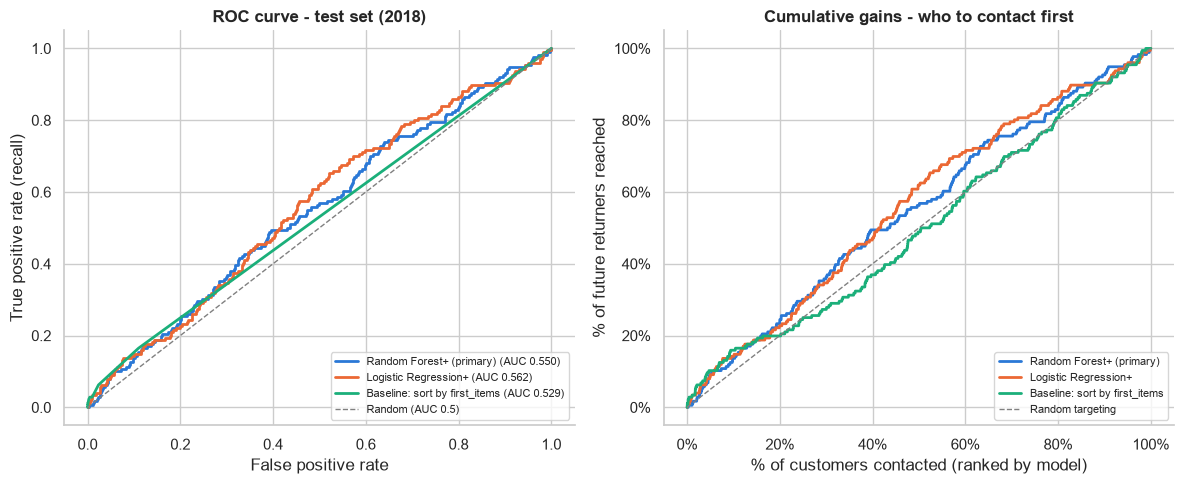

In [62]:
COLORS = {"Random Forest+ (primary)": "#2a78d6", "Logistic Regression+": "#eb6834",
          "Baseline: sort by first_items": "#1baf7a"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Left: ROC curves
for name, color in COLORS.items():
    fpr, tpr, _ = roc_curve(yt, scores[name])
    ax1.plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC {test_tbl.loc[name, 'roc_auc']:.3f})")
ax1.plot([0, 1], [0, 1], color="gray", ls="--", lw=1, label="Random (AUC 0.5)")
ax1.set_title("ROC curve - test set (2018)")
ax1.set_xlabel("False positive rate")
ax1.set_ylabel("True positive rate (recall)")
ax1.legend(fontsize=8, loc="lower right")

# Right: cumulative gains - % of returners reached vs % of customers contacted
x = np.arange(1, len(yt) + 1) / len(yt) * 100
for name, color in COLORS.items():
    o = np.argsort(-scores[name])
    ax2.plot(x, np.cumsum(yt[o]) / total_pos * 100, color=color, lw=2, label=name)
ax2.plot([0, 100], [0, 100], color="gray", ls="--", lw=1, label="Random targeting")
ax2.set_title("Cumulative gains - who to contact first")
ax2.set_xlabel("% of customers contacted (ranked by model)")
ax2.set_ylabel("% of future returners reached")
ax2.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax2.legend(fontsize=8, loc="lower right")

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(IMG_DIR / "11_model_evaluation.png", dpi=150, bbox_inches="tight")
plt.show()

                  feature  importance    std
              first_items      0.0101 0.0024
         max_installments      0.0081 0.0084
             log_distance      0.0080 0.0066
       cat_sports_leisure      0.0040 0.0071
       cat_bed_bath_table      0.0034 0.0026
                 state_SP      0.0034 0.0032
cat_computers_accessories      0.0032 0.0019
        same_state_seller      0.0029 0.0022
        cat_health_beauty      0.0018 0.0017
              state_Other      0.0017 0.0016
              pay_voucher      0.0014 0.0010
             first_orders      0.0012 0.0016
                cat_Other      0.0012 0.0026
                n_sellers      0.0012 0.0030
      cat_furniture_decor      0.0010 0.0009


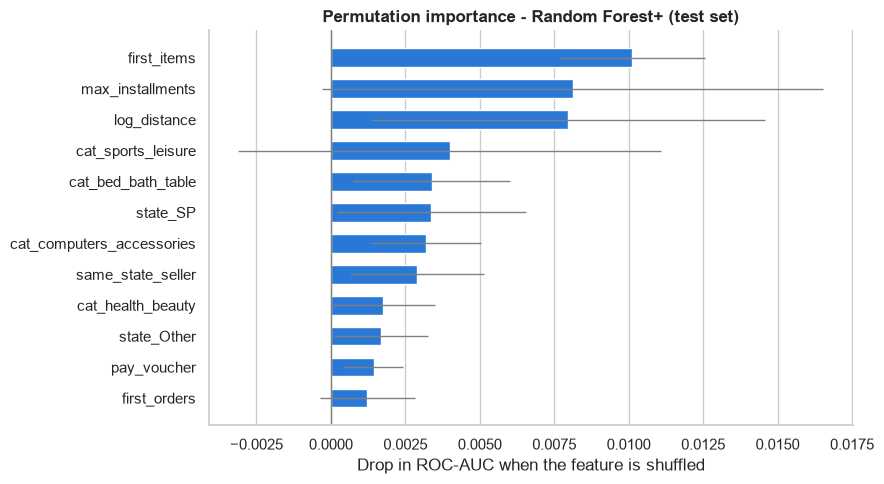

In [63]:
from sklearn.inspection import permutation_importance

# How much does test ROC-AUC drop when one feature is shuffled? (bigger drop = more important)
perm = permutation_importance(final_rf, X_RF.loc[X_test.index], y_test, scoring="roc_auc",
                              n_repeats=5, random_state=42, n_jobs=-1)
imp = (pd.DataFrame({"feature": X_RF.columns,
                     "importance": perm.importances_mean,
                     "std": perm.importances_std})
         .sort_values("importance", ascending=False))
print(imp.head(15).round(4).to_string(index=False))

top = imp.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top["feature"], top["importance"], xerr=top["std"], color="#2a78d6", height=0.6,
        error_kw={"ecolor": "gray", "lw": 1})
ax.axvline(0, color="gray", lw=1)
ax.set_title("Permutation importance - Random Forest+ (test set)")
ax.set_xlabel("Drop in ROC-AUC when the feature is shuffled")
ax.grid(axis="y", visible=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(IMG_DIR / "12_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight - an honest result: the model is only slightly better than random**

**Test set (2018): 13,564 customers, 176 returners (1.30%).**

| Model | ROC-AUC | 95% CI | PR-AUC lift |
|---|---|---|---|
| Random Forest+ (primary) | **0.550** | 0.506 - 0.593 | 1.20 |
| Logistic Regression+ | 0.562 | 0.518 - 0.602 | 1.44 |
| Baseline: sort by first_items | 0.529 | 0.503 - 0.559 | 1.43 |
| Random | 0.464 | 0.419 - 0.502 | 0.95 |

- Both models are **above random** (their confidence intervals stay above 0.5), but only **slightly**. The Random Forest also dropped from 0.582 on validation to 0.550 on test, a normal loss when a model meets a new period.
- The two models are statistically the same (their intervals overlap almost completely). We keep the Random Forest as the primary model because it was chosen **before** the test; switching now would be choosing on the test set.
- The models are **not clearly better than a one-line rule** ("sort by number of items"), which has almost the same PR-AUC.
- **Targeting with the model:** contacting the top **5%** reaches 16 future returners instead of ~9 at random (**lift 1.8**); top 10% -> lift 1.4; top 20% -> 24% of returners (lift 1.2). Useful only at the very top, and the numbers are small.
- **What the model relies on** (permutation importance): number of items in the first order, payment installments, customer-seller distance, product category (sports_leisure, bed_bath_table, computers_accessories, health_beauty), state SP and same-state seller.

**Conclusion for the business:**
- With only first-order information, **a second purchase cannot be predicted reliably** at the customer level: the decision to come back depends on things the data does not contain (needs, competitors, marketing contact).
- Practical recommendation: use **simple, explainable rules** for second-purchase campaigns: high-return **categories** (sports, perfumery, home items), **multi-item** first orders, and the **RFM segment** (New high-value). The model probability is exported as a *ranking aid*, not as a decision rule.
- Bigger levers are **operational**: on-time delivery (protects the fast second purchase) and **post-delivery follow-up in the first month**.

**For interviews:** the value of this part is the method (no leakage, time-based validation, baseline, confidence intervals) and the honest reading of a weak result, not a high score.
